# Tutorial 0 — One scene, forty windows, four figures

**A companion 150 mas from a star, drifting at a few mas per year, is seen
in nothing but one-dimensional brightness profiles taken along the scan
direction. This page renders those windows, draws the three images one can
make of them, and then measures the companion by fitting all the windows at
once.** It uses the public names of `scanlib` only, in the order a campaign
is processed, and runs in well under a minute.

Conventions throughout: angles in radians, the scan angle ψ counter-clockwise
from north; sky offsets (Δα\*, Δδ) in mas from the primary; the along-scan
coordinate η = Δα\* sin ψ + Δδ cos ψ in mas; epochs τ in years from the
reference epoch; proper motions in mas/yr; fluxes per sample in the windows'
units; Gaussian noise of known σ.

| block | task | calls | paper |
|---|---|---|---|
| 1 | the instrument and one window | `ins.Instrument.gaussian`, `ins.render_window` | Sect. 2.1, Eqs. 3–4 |
| 2 | the scene, the scan law, the forty windows as a sinogram | `joint.scene_positions_al`, `sim.simulate_window`, `ins.project_al` | Sects. 3.1, 4.2; Eqs. 9, 16 |
| 3 | detections (a stand-in for the per-window reduction) | `inst.design_columns`, `inst.design_jacobian` | Sect. 2.2, Eq. 8; App. B.1 |
| 4 | three images: the map, the inverse Radon transform, faststack | `bp.backprojection_map`, `bp.map_peak`, `radon.filtered_backprojection`, `radon.faststack` | Sect. 3.3, Eq. 13; App. C.2, Eq. C.3 |
| 5 | the joint fit of all windows | `joint.fit_joint` | Sect. 4.3, Eq. 18 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** This page, then one page per image: [the inverse Radon transform](01_inverse_radon.ipynb), [faststack](02_faststack.ipynb), [the triangulation map](03_triangulation_map.ipynb); then where each step's premise breaks, in [`limitations/`](limitations/). The pipeline itself, from the windows to the measurement, is in [`../quickstart/`](../quickstart/).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../docs/conventions.md). This page uses ψ, (Δα\*, Δδ), η, η₀, τ, μ, θ and θ₀, σ_η and the detections, the map, the inverse Radon transform, faststack, the Fisher σ and χ²/dof.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name.
# Then the one random generator of this page; the seed makes every number below reproducible
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

# the seed is one number, 5: a label only (why 5: not stated). The generator's draws, in order: the noise of the
# forty windows (block 2), then the errors of the detections (block 3)
rng = np.random.default_rng(5)

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
# TRUTH, FIT, PRIMARY: three tables of options for ax.scatter (the marker, its size, its colours, its line
# width, its drawing order), one per kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
FIT = dict(marker="x", s=70, color="k", lw=1.5, zorder=8)                             # a measurement (the joint fit)
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, panel_letter, text=""):
    """Write the panel letter, bold, inside the top-left corner of a panel, and a few words after it.

    Inputs
        ax             the panel (a matplotlib Axes)
        panel_letter   the letter, for example "a"
        text           the words after the letter
    Returns nothing."""
    ax.text(0.04, 0.96, rf"$\bf{{({panel_letter})}}$ " + text, transform=ax.transAxes, va="top", ha="left",
            fontsize=9, bbox=dict(fc="white", ec="none", pad=1.0, alpha=0.8))

## 1. The instrument

*Paper: Sect. 2.1, Eqs. 3–4.*

**A window is the strip of samples the instrument reads out along the scan
each time the star crosses the focal plane.** The toy instrument here is
one Gaia AF window: 18 samples 59 mas apart, blurred by a Gaussian
line-spread function (LSF) of full width at half maximum 100 mas. The
operator `inst.design_columns` gives the samples a unit flux at each position
produces; `ins.render_window` is that operator times the fluxes.

In [3]:
# the instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of FWHM 100 mas, and the trial
# positions of the per-window reduction
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                 # sample centers along the scan [mas]
sigma_lsf = 100.0 / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # Gaussian LSF sigma for FWHM 100 mas
# grid[1] - grid[0]: the distance between the first two sample centers, the pitch [mas]
print(f"{grid.size} samples, pitch {grid[1] - grid[0]:.0f} mas, LSF sigma {sigma_lsf:.1f} mas")

18 samples, pitch 59 mas, LSF sigma 42.5 mas


In [4]:
# a star and a companion 150 mas along the scan: their noise-free window. ins.render_window is the operator
# inst.design_columns times the fluxes
eta_pair = np.array([0.0, 150.0])            # along-scan positions [mas]
flux_pair = np.array([1000.0, 300.0])        # fluxes, in flux per sample
samples = ins.render_window(eta_pair, flux_pair, inst)

In [5]:
# The model profile on a fine display grid: the same operator evaluated at
# other sample centers. It integrates the LSF over one sample of the
# instrument's 59 mas pitch, so the curve is in flux per sample, the unit of
# the samples.
# grid[0] and grid[-1] are the first and the last sample center; the display grid runs 100 mas past each
fine = np.linspace(grid[0] - 100.0, grid[-1] + 100.0, 600)
# unit_profiles: one column per source, the profile a unit flux at its position produces on the display grid;
# unit_profiles @ flux_pair is the sum of the columns, each times its flux
unit_profiles = inst.design_columns(eta_pair, sample_grid_mas=fine)
curve = unit_profiles @ flux_pair

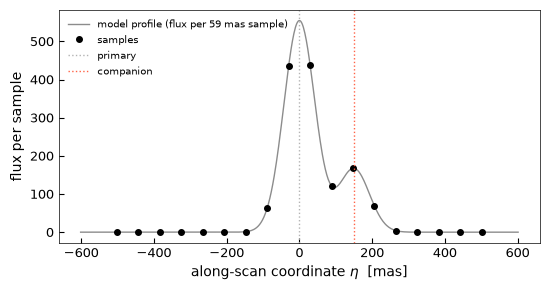

In [6]:
# Figure 1: the samples of the window, the model profile, and the two positions
fig, ax = plt.subplots(figsize=(5.6, 3.0))
ax.plot(fine, curve, color="0.55", lw=1, label="model profile (flux per 59 mas sample)")
ax.plot(grid, samples, "o", color="k", ms=4, label="samples")
# eta_pair[0] is the primary's position, eta_pair[1] the companion's
ax.axvline(eta_pair[0], color="0.7", ls=":", lw=1, label="primary")
ax.axvline(eta_pair[1], color=ACCENT, ls=":", lw=1, label="companion")
ax.set(xlabel=r"along-scan coordinate $\eta$  [mas]", ylabel="flux per sample")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. The scene and the scan law

*Paper: Sects. 3.1 and 4.2; Eq. 9 (the projection), Eq. 16 (with motion and parallax).*

**The scan law is the list of transits, each with its scan angle ψ, its
epoch τ and its along-scan parallax factor.** The 40 transits below are the
first 40 of the public Gaia scan-law forecast for the Pleiades center,
stored with the package's reference cases (only the sky position matters).
The scene is a primary at the origin and a companion at separation 150 mas,
position angle −50° (from north through east), with 30 % of the primary's
flux, drifting at (μα\*, μδ) = (6, −4) mas/yr with a parallax difference of
−5 mas. Those five numbers are the parameter vector the fit must recover.
`joint.scene_positions_al` projects the scene into every window, and
`sim.simulate_window` renders each one with noise of σ = 10 flux units (the
primary's total flux is 100 σ). Figure 2 draws the forty windows as a
*sinogram*: each window is a strip at its scan angle, from 0 to 360°, with
η upward, as in the paper's Fig. 3 and in the quickstart. The primary sits
at η = 0 in every strip;
the companion's position follows the sinusoid η = Δα\* sin ψ + Δδ cos ψ,
and the drift and the parallax move it a little off the curve. Where the
sinusoid crosses η = 0 the two stars are blended in the window. The
forecast scans a few bundles of directions, which is why the strips
cluster.

In [7]:
# the scan law from the reference cases (scan angle, epoch, parallax factor), and the scene's parameters
ref = np.load("../../tests/reference/reference_cases.npz")
psi = ref["moving_pair/inputs/psi"]          # the scan angle of each transit [rad]
tau = ref["moving_pair/inputs/tau"]          # its epoch [yr from the reference epoch]
fpar = ref["moving_pair/inputs/fpar"]        # its along-scan parallax factor
rho = 150.0                                  # the companion's separation [mas]
position_angle = np.deg2rad(-50.0)           # its position angle, from north through east [rad]
# theta_true: the five parameters of the companion, (Δα*, Δδ) [mas], (μα*, μδ) [mas/yr], Δϖ [mas]
theta_true = np.array([rho * np.sin(position_angle), rho * np.cos(position_angle), 6.0, -4.0, -5.0])
flux = np.array([1000.0, 300.0])             # the fluxes per sample, primary first
sigma_noise = 10.0                           # the noise sigma of one sample, in the fluxes' unit

In [8]:
# the along-scan position of both sources in every window (Eq. 16), then one noisy window per transit
eta_true = joint.scene_positions_al(theta_true, psi, tau, fpar)      # (40, 2): primary, companion
# sim.simulate_window renders the window of transit j and adds its noise, drawn from rng; the windows are made
# in the order of the transits, so the draws are in that order too
windows = []
for j in range(psi.size):                                            # j counts the transits
    windows.append(sim.simulate_window(eta_true[j], flux, inst, rng, sigma_noise))
windows = np.array(windows)                                          # (40, 18): one row per transit
campaign_length = tau.max() - tau.min()                              # from the first epoch to the last [yr]
print(f"{psi.size} transits over {campaign_length:.1f} yr; windows {windows.shape}")

40 transits over 4.6 yr; windows (40, 18)


In [9]:
# Figure 2: the sinogram. Each window is drawn as a strip at its scan angle, 0 to 360 deg, in a square-root
# stretch. The primary sits at eta = 0 in every strip; the companion's eta follows the sinusoid
# eta = dra* sin(psi) + ddec cos(psi), drawn for the reference epoch, with the drift and the parallax moving
# it a little off the curve.
# np.r_ joins the left edges of the 18 samples and the last right edge: 19 edges for pcolormesh
pitch = grid[1] - grid[0]
edges = np.r_[grid - pitch / 2, grid[-1] + pitch / 2]
angle = np.degrees(np.mod(psi, 2 * np.pi))            # the forecast's angles run from -180 to 180 deg

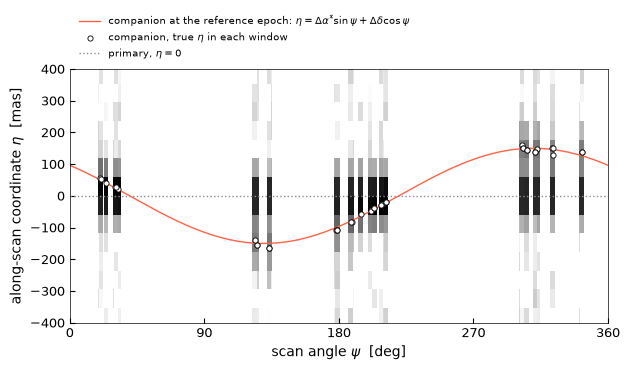

In [10]:
# the strips, the companion's sinusoid at the reference epoch, its true position in each window, the primary.
# [:, None] makes the 18 samples of a window a strip of 18 x 1 pixels
fig, ax = plt.subplots(figsize=(6.4, 3.8))
gray_top = np.sqrt(windows.max())                 # the top of the gray scale: the brightest sample, stretched
for strip_angle, window in zip(angle, windows):
    stretched = np.sqrt(np.clip(window, 0, None))                # negative samples set to zero, then the square root
    strip_sides = [strip_angle - 1.5, strip_angle + 1.5]         # the strip is 3 deg wide [deg]
    ax.pcolormesh(strip_sides, edges, stretched[:, None], cmap="gray_r", vmin=0, vmax=gray_top, rasterized=True)
# one full turn of scan angles [rad], and the companion's along-scan position at each (Eq. 9), from the first
# two entries of theta_true: its (Δα*, Δδ) at the reference epoch
turn = np.linspace(0.0, 2 * np.pi, 721)
sinusoid = ins.project_al(theta_true[0], theta_true[1], turn)
ax.plot(np.degrees(turn), sinusoid, color=ACCENT, lw=1,
        label=r"companion at the reference epoch: $\eta = \Delta\alpha^{*}\sin\psi + \Delta\delta\cos\psi$")
# truth: eta_true[:, 1] is the companion's column (column 0 is the primary), one value per window
ax.scatter(angle, eta_true[:, 1], s=14, facecolor="white", edgecolor="k", lw=0.6, zorder=5,
           label=r"companion, true $\eta$ in each window")
ax.axhline(0.0, color="0.55", ls=":", lw=1, label=r"primary, $\eta = 0$")
ax.set(xlim=(0, 360), xticks=np.arange(0, 361, 90), ylim=(-400, 400),
       xlabel=r"scan angle $\psi$  [deg]", ylabel=r"along-scan coordinate $\eta$  [mas]")
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0))
plt.tight_layout()
plt.show()

## 3. Detections

*Paper: Sect. 2.2, Eq. 8 (the detection set); App. B.1 (the error of a position in one window).*

**The back-projection map pools detections: one along-scan position per
window in which the companion was resolved, with its uncertainty.**
The package makes detections from the windows with the per-window
reduction (`reduce_campaign`; quickstart 1, block 5). This page is about
the images and the fit, so it uses a stand-in: the detections are the truth
plus the error a window's own Fisher matrix predicts, the model's
derivatives with respect to the companion's position and the two fluxes,
from `inst.design_jacobian` and `inst.design_columns`. A window in which
that error exceeds 30 mas, because the scan ran across the pair and blended
them, delivers nothing. That rule is the stand-in's; the reduction's rule is
in [`docs/conventions.md`](../../docs/conventions.md).

In [11]:
# the stand-in's error: the Fisher sigma of the companion's along-scan position in one window
def sigma_eta(eta, flux, inst, sigma_noise):
    """The error that one window's Fisher matrix predicts for the companion's along-scan position, with the two
    fluxes free. The stand-in of this block draws each detection's error from it.

    Inputs
        eta           the along-scan positions of the two sources in the window [mas], primary first
        flux          their fluxes per sample, primary first
        inst          the instrument
        sigma_noise   the noise sigma of one sample, in the fluxes' unit
    Returns
        the Fisher 1-sigma of the companion's position [mas], a float; infinite where the Fisher matrix is
        singular"""
    # step 1, the model's pieces. unit_profiles: one column per source, the samples a unit flux at its position
    # produces. profile_slopes: the derivative of each column with respect to its source's position [1/mas]
    unit_profiles = inst.design_columns(eta)
    profile_slopes = inst.design_jacobian(eta)

    # step 2, the Jacobian of the window's model with respect to three parameters: the companion's position
    # (column 1 of profile_slopes times the companion's flux, flux[1]), then the two fluxes (the two columns of
    # unit_profiles)
    jacobian = np.column_stack([profile_slopes[:, 1] * flux[1], unit_profiles])

    # step 3, the Fisher matrix of the three parameters; a condition number above 1e12 counts as singular
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    if np.linalg.cond(fisher) > 1e12:
        return np.inf

    # step 4, the inverse of the Fisher matrix is the covariance; [0, 0] is the variance of the first parameter,
    # the companion's position
    covariance = np.linalg.inv(fisher)
    return float(np.sqrt(covariance[0, 0]))

In [12]:
# truth: the error in every window, and a detection where it is below 30 mas: the true position plus a draw of
# that error. The mask `resolved` keeps those windows; eta_true[resolved, 1] is their companion column (column
# 0 is the primary)
SIGMA_MAX_MAS = 30.0                          # the stand-in's rule: a window with a larger error delivers nothing [mas]
sigma_every_window = []
for j in range(psi.size):                     # j counts the transits
    sigma_every_window.append(sigma_eta(eta_true[j], flux, inst, sigma_noise))
sigma_every_window = np.array(sigma_every_window)
resolved = sigma_every_window <= SIGMA_MAX_MAS
det_psi = psi[resolved]                       # the detections' scan angles [rad]
det_sigma = sigma_every_window[resolved]      # the detections' errors [mas]
# one standard normal draw per detection, from the page's generator (after the windows' noise)
unit_draws = rng.normal(0.0, 1.0, det_sigma.size)
det_eta = eta_true[resolved, 1] + unit_draws * det_sigma
print(f"{resolved.sum()} of {psi.size} windows resolve the companion; "
      f"median sigma_eta {np.median(det_sigma):.1f} mas")

40 of 40 windows resolve the companion; median sigma_eta 3.4 mas


## 4. Three images

*Paper: Sect. 3.3, Eq. 13 (the map); App. C.2, Eq. C.3 (the inverse Radon transform) and its text on faststack.*

**Each detection fixes the companion on a line of the sky; the back-projection
map sums one unit-area Gaussian ridge per line, and the companion is where
they cross.** Beside it, two images of the windows themselves: the inverse
Radon transform (`radon.filtered_backprojection`, each window ramp-filtered and laid
back along its scan line) and faststack (`radon.faststack`, the robust stack of the
samples). Both are pictures, not measurements: the companion drifts by
some 30 mas over the campaign, and the two images, which assume a static
sky, smear it, while the map's peak gives the seed of the fit.

In [13]:
# the three images on the same sky grid (half-size 300 mas, 4 mas pixels), and the map's peak, the seed of the
# fit. Each call returns more than the image (its axis, its extent, a variance); `_` drops what is not used
half = 300.0                                 # the half-size of the sky grid [mas]
step = 4.0                                   # its pixel [mas]
PEAK_STEP_MAS = 1.0                          # the pixel of the finer map on which the peak is read [mas]
sky, axis, extent = bp.backprojection_map(det_psi, det_eta, det_sigma, half, step)
image, _ = radon.filtered_backprojection(psi, windows, inst, half, step)
stack, variance, n_used, _ = radon.faststack(psi, windows, inst, half, step)
# bp.map_peak returns the peak (Δα*, Δδ) [mas], the map's width there [mas], then the finer map and its axis
peak, width, _, _ = bp.map_peak(det_psi, det_eta, det_sigma, half, PEAK_STEP_MAS)
# truth: the peak against the true position, the first two entries of theta_true
print(f"map peak at ({peak[0]:.0f}, {peak[1]:.0f}) mas, width {width:.1f} mas; "
      f"truth ({theta_true[0]:.0f}, {theta_true[1]:.0f}) mas at the reference epoch")

map peak at (-119, 102) mas, width 6.1 mas; truth (-115, 96) mas at the reference epoch


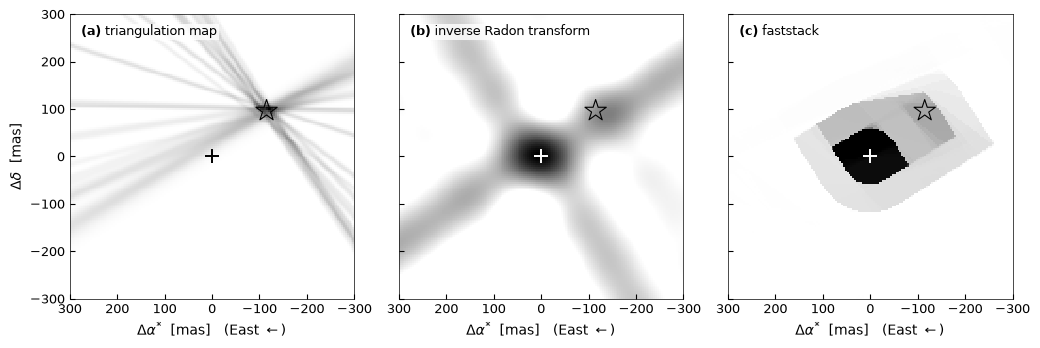

In [14]:
# Figure 3: the three images side by side; the primary (plus) and the companion's true position at the
# reference epoch (star)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.8), sharex=True, sharey=True)
images = (sky, image, stack)
panel_names = ("triangulation map", "inverse Radon transform", "faststack")
for ax, shown, panel_letter, name in zip(axes, images, "abc", panel_names):
    ax.imshow(shown, origin="lower", extent=extent, cmap="gray_r", vmin=0, interpolation="nearest", rasterized=True)
    # the primary: a plus, white where the image is dark at the primary; the truth: an open star, so that the
    # image shows inside it
    if panel_letter == "a":
        primary_colour = "k"
    else:
        primary_colour = "w"
    # {**TABLE, "key": value}: a copy of the table of options with that one entry replaced or added
    primary_style = {**PRIMARY, "color": primary_colour}
    truth_style = {**TRUTH, "facecolor": "none", "s": 260}
    ax.scatter(0, 0, **primary_style)
    ax.scatter(theta_true[0], theta_true[1], **truth_style)
    letter(ax, panel_letter, name)
    ax.set_aspect("equal")
    ax.set_xlim(half, -half)                                     # east to the left
    ax.set_xlabel(EAST)
axes[0].set_ylabel(NORTH)
plt.tight_layout()
plt.show()

## 5. The joint fit

*Paper: Sect. 4.3, Eq. 18.*

**`joint.fit_joint`, given the epochs `tau`, fits all forty windows at once: at every trial set of
motions the two fluxes are solved by non-negative least squares, and
Nelder-Mead, restarted until a restart stops helping, maximizes the profiled
likelihood.** The seed is the map's peak with the motions at zero;
initialization only, never data. The result carries the parameters, the
fluxes, the inverse Fisher covariance and the log-likelihood at the
solution. The figure shows the fitted position with its covariance
ellipses at Mahalanobis radius 1 and 3 (the legend's 1σ and 3σ), which in
two dimensions enclose 39.3 % and 98.9 % of the probability, not 68 % and
99.7 % ([conventions](../../docs/conventions.md)), against the truth, and
the fitted drift.

In [15]:
# the fit, started at the map's peak with the motions and the parallax difference at zero
theta0 = np.array([peak[0], peak[1], 0.0, 0.0, 0.0])        # (Δα*, Δδ) of the peak, then μα*, μδ, Δϖ at zero
# fit: a table (a dictionary) of the results; the next cells read its entries "theta", "sigma_theta", "cov",
# "flux", "chi2", "loglike", "n_restarts" and "converged"
fit = joint.fit_joint(windows, psi, theta0, inst, sigma_noise, tau=tau, fpar=fpar)

In [16]:
# truth: the table of each parameter (truth, fit, error, pull), then the fluxes and the fit's summary
names = ("Δα* [mas]", "Δδ [mas]", "μα* [mas/yr]", "μδ [mas/yr]", "Δϖ [mas]")
print(f"{'parameter':14s} {'truth':>9s} {'fit':>9s} {'sigma':>7s} {'pull':>6s}")
for name, true_value, fitted, error in zip(names, theta_true, fit["theta"], fit["sigma_theta"]):
    pull = (fitted - true_value) / error             # the fit's offset from the truth, in units of its error
    print(f"{name:14s} {true_value:9.2f} {fitted:9.2f} {error:7.2f} {pull:6.2f}")
print(f"fluxes {fit['flux'].round(1)} (truth {flux}); chi2 {fit['chi2']:.1f} "
      f"for {windows.size} samples; log-likelihood {fit['loglike']:.1f}; "
      f"{fit['n_restarts']} restarts, converged {fit['converged']}")

parameter          truth       fit   sigma   pull
Δα* [mas]        -114.91   -116.43    0.95  -1.61
Δδ [mas]           96.42     94.59    0.75  -2.43
μα* [mas/yr]        6.00      5.22    0.77  -1.01
μδ [mas/yr]        -4.00     -3.97    0.44   0.06
Δϖ [mas]           -5.00     -5.01    1.05  -0.01
fluxes [1000.3  300. ] (truth [1000.  300.]); chi2 700.0 for 720 samples; log-likelihood -2669.5; 2 restarts, converged True


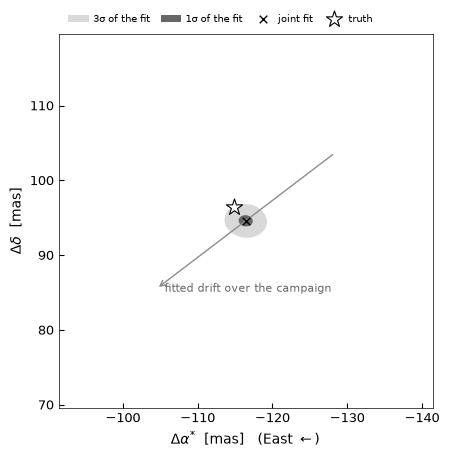

In [17]:
# Figure 4: the fitted position (cross) with its covariance ellipses, the truth (star), and the fitted drift over
# the campaign (arrow).
# fit["cov"][:2, :2] is the 2 x 2 block of the position; fit["theta"][2:4] is the proper motion
fig, ax = plt.subplots(figsize=(4.6, 4.9))
fitted_position = fit["theta"][:2]                   # the first two parameters: (Δα*, Δδ) [mas]
fitted_motion = fit["theta"][2:4]                    # the third and the fourth: (μα*, μδ) [mas/yr]
position_cov = fit["cov"][:2, :2]
# the ellipse's axes: the eigenvalues come in ascending order, so [1] is the long axis and [0] the short one;
# column 1 of the eigenvectors is the direction of the long axis, and ellipse_angle its angle [deg]
eigenvalues, eigenvectors = np.linalg.eigh(position_cov)
ellipse_angle = np.degrees(np.arctan2(eigenvectors[1, 1], eigenvectors[0, 1]))
for k, gray in ((3, "0.85"), (1, "0.40")):           # k: the Mahalanobis radius of the ellipse, 3 then 1
    ax.add_patch(Ellipse(fitted_position, 2 * k * np.sqrt(eigenvalues[1]), 2 * k * np.sqrt(eigenvalues[0]),
                         angle=ellipse_angle, color=gray, lw=0, label=f"{k}σ of the fit"))
fit_style = {**FIT, "s": 30, "lw": 1.0}              # the FIT table with a smaller, thinner cross
ax.scatter(fitted_position[0], fitted_position[1], **fit_style, label="joint fit")
ax.scatter(theta_true[0], theta_true[1], **TRUTH, label="truth")
# the arrow: the fitted proper motion times the campaign's length, centered on the fitted position
drift = fitted_motion * campaign_length
arrow_head = fitted_position + drift / 2
arrow_tail = fitted_position - drift / 2
ax.annotate("", xy=arrow_head, xytext=arrow_tail, arrowprops=dict(arrowstyle="->", color="0.55"))
ax.text(arrow_head[0], arrow_head[1], "  fitted drift over the campaign", color="0.4", fontsize=8, va="center")
ax.set(xlabel=EAST, ylabel=NORTH, aspect="equal")
ax.set_xlim(fitted_position[0] + 25, fitted_position[0] - 25)    # east to the left
ax.set_ylim(fitted_position[1] - 25, fitted_position[1] + 25)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4, columnspacing=1.0, handletextpad=0.4)
plt.tight_layout()
plt.show()

## Where to read next

The likelihood, the profiling and the Fisher matrix are written out in the
module docstring of `scanlib.joint`; the unit-area ridge in
`scanlib.backprojection`; the ramp filter, the half-turn weights and
Harrison's weights in `scanlib.radon`. `tests/test_reference_cases.py` runs
every function here against the stored reference cases (`tests/reference/`).